In [2]:
import numpy as np 
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/mervebzn/weatherdata/Weather_Data.csv


In [3]:
df = pd.read_csv("/kaggle/input/datasets/mervebzn/weatherdata/Weather_Data.csv")
df.head(20)

,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2/1/2008,19.5,22.4,15.6,6.2,0.0,W,41,S,SSW,...,92,84,1017.6,1017.4,8,8,20.7,20.9,Yes,Yes
1,2/2/2008,19.5,25.6,6.0,3.4,2.7,W,41,W,E,...,83,73,1017.9,1016.4,7,7,22.4,24.8,Yes,Yes
2,2/3/2008,21.6,24.5,6.6,2.4,0.1,W,41,ESE,ESE,...,88,86,1016.7,1015.6,7,8,23.5,23.0,Yes,Yes
3,2/4/2008,20.2,22.8,18.8,2.2,0.0,W,41,NNE,E,...,83,90,1014.2,1011.8,8,8,21.4,20.9,Yes,Yes
4,2/5/2008,19.7,25.7,77.4,4.8,0.0,W,41,NNE,W,...,88,74,1008.3,1004.8,8,8,22.5,25.5,Yes,Yes
5,2/6/2008,20.2,27.2,1.6,2.6,8.6,W,41,W,ENE,...,69,62,1002.7,998.6,6,6,23.8,26.0,Yes,Yes
6,2/7/2008,18.6,26.3,6.2,5.2,5.2,W,41,W,S,...,75,80,999.0,1000.3,4,7,21.7,22.3,Yes,Yes
7,2/8/2008,17.2,22.3,27.6,5.8,2.1,W,41,S,SE,...,77,61,1008.3,1007.4,7,8,18.9,21.1,Yes,Yes
8,2/9/2008,16.4,20.8,12.6,4.8,3.0,W,41,SSW,W,...,92,91,1006.4,1007.6,7,7,17.1,16.5,Yes,Yes
9,2/10/2008,14.6,24.2,8.8,4.4,10.1,W,41,W,SSE,...,80,53,1014.0,1013.4,4,2,17.2,23.3,Yes,No


# Initial Exploration

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3271 entries, 0 to 3270
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           3271 non-null   object 
 1   MinTemp        3271 non-null   float64
 2   MaxTemp        3271 non-null   float64
 3   Rainfall       3271 non-null   float64
 4   Evaporation    3271 non-null   float64
 5   Sunshine       3271 non-null   float64
 6   WindGustDir    3271 non-null   object 
 7   WindGustSpeed  3271 non-null   int64  
 8   WindDir9am     3271 non-null   object 
 9   WindDir3pm     3271 non-null   object 
 10  WindSpeed9am   3271 non-null   int64  
 11  WindSpeed3pm   3271 non-null   int64  
 12  Humidity9am    3271 non-null   int64  
 13  Humidity3pm    3271 non-null   int64  
 14  Pressure9am    3271 non-null   float64
 15  Pressure3pm    3271 non-null   float64
 16  Cloud9am       3271 non-null   int64  
 17  Cloud3pm       3271 non-null   int64  
 18  Temp9am 

In [5]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000,3271.000000
mean,14.877102,23.005564,3.342158,5.175787,7.168970,41.476307,15.077041,19.294405,68.243962,54.698563,1018.334424,1016.003085,4.318557,4.176093,17.821461,21.543656
std,4.554710,4.483752,9.917746,2.757684,3.815966,10.806951,7.043825,7.453331,15.086127,16.279241,7.020090,7.019915,2.526923,2.411274,4.894316,4.297053
min,4.300000,11.700000,0.000000,0.000000,0.000000,17.000000,0.000000,0.000000,19.000000,10.000000,986.700000,989.800000,0.000000,0.000000,6.400000,10.200000
25%,11.000000,19.600000,0.000000,3.200000,4.250000,35.000000,11.000000,15.000000,58.000000,44.000000,1013.700000,1011.300000,2.000000,2.000000,13.800000,18.400000
50%,14.900000,22.800000,0.000000,4.800000,8.300000,41.000000,15.000000,19.000000,69.000000,56.000000,1018.600000,1016.300000,5.000000,4.000000,18.200000,21.300000
75%,18.800000,26.000000,1.400000,7.000000,10.200000,44.000000,20.000000,24.000000,80.000000,64.000000,1023.100000,1020.800000,7.000000,7.000000,21.700000,24.500000
max,27.600000,45.800000,119.400000,18.400000,13.600000,96.000000,54.000000,57.000000,100.000000,99.000000,1039.000000,1036.700000,9.000000,8.000000,36.500000,44.700000


In [6]:
df.isna().sum()

Date             0
MinTemp          0
MaxTemp          0
Rainfall         0
Evaporation      0
Sunshine         0
WindGustDir      0
WindGustSpeed    0
WindDir9am       0
WindDir3pm       0
WindSpeed9am     0
WindSpeed3pm     0
Humidity9am      0
Humidity3pm      0
Pressure9am      0
Pressure3pm      0
Cloud9am         0
Cloud3pm         0
Temp9am          0
Temp3pm          0
RainToday        0
RainTomorrow     0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
# COnvert Date
df['Date'] = pd.to_datetime(df['Date'], format = '%m/%d/%Y')

print(df['Date'].dtype)
print(df['Date'].min(), '-' , df['Date'].max())

datetime64[ns]
2008-02-01 00:00:00 - 2017-06-25 00:00:00


# Data Cleaning

In [9]:
# Convert categoricals
cat_col = ['WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']
for col in cat_col:
    df[col]= df[col].astype('category')

df.dtypes

Date             datetime64[ns]
MinTemp                 float64
MaxTemp                 float64
Rainfall                float64
Evaporation             float64
Sunshine                float64
WindGustDir            category
WindGustSpeed             int64
WindDir9am             category
WindDir3pm             category
WindSpeed9am              int64
WindSpeed3pm              int64
Humidity9am               int64
Humidity3pm               int64
Pressure9am             float64
Pressure3pm             float64
Cloud9am                  int64
Cloud3pm                  int64
Temp9am                 float64
Temp3pm                 float64
RainToday              category
RainTomorrow           category
dtype: object

In [10]:
# Check missing dates
full_range = pd.date_range(df['Date'].min(), df['Date'].max(), freq = 'D')
missing_dates  = full_range.difference(df['Date'])

print('Expected days:', len(full_range))
print('Actual days:', len(df))
print('Missing days:', len(missing_dates))

Expected days: 3433
Actual days: 3271
Missing days: 162


In [11]:
# Document data quality note
print(f"Note: {len(missing_dates)} days ({len(missing_dates)/len(full_range)*100:.2f}%) "
      f"are missing from the date range and were intentionally left as gaps "
      f"rather than interpolated, to avoid introducing fabricated values.")

Note: 162 days (4.72%) are missing from the date range and were intentionally left as gaps rather than interpolated, to avoid introducing fabricated values.


In [12]:
# Check MinTemp vs MaxTemp
issue1 = (df['MinTemp']> df['MaxTemp'].sum())
print('MinTemp > MaxTemp:', issue1)

MinTemp > MaxTemp: 0       False
1       False
2       False
3       False
4       False
        ...  
3266    False
3267    False
3268    False
3269    False
3270    False
Name: MinTemp, Length: 3271, dtype: bool


In [13]:
# Check humidity range
issue2 = ((df['Humidity9am'] < 0) | (df['Humidity9am'] > 100)).sum()
issue3 = ((df['Humidity3pm'] < 0) | (df['Humidity3pm'] > 100)).sum()

print('Humidity9am out of range:', issue2)
print('Humidity3pm out of range:', issue3)

Humidity9am out of range: 0
Humidity3pm out of range: 0


In [14]:
# Check humidity range
issue2 = ((df['Humidity9am'] < 0) | (df['Humidity9am'] > 100)).sum()
issue3 = ((df['Humidity3pm'] < 0) | (df['Humidity3pm'] > 100)).sum()

print('Humidity9am out of range:', issue2)
print('Humidity3pm out of range:', issue3)

Humidity9am out of range: 0
Humidity3pm out of range: 0


In [15]:
# Check negative rainfall
issue4 = (df['Rainfall'] < 0).sum()

print('Negative rainfall:', issue4)

Negative rainfall: 0


In [16]:
# Check RainToday vs Rainfall consistency
issue5 = (((df['RainToday'] == 'Yes') & (df['Rainfall'] == 0)) |
          ((df['RainToday'] == 'No') & (df['Rainfall'] > 1))).sum()

print('RainToday/Rainfall mismatch:', issue5)

RainToday/Rainfall mismatch: 0


In [17]:
# Detect outliers with IQR
numeric_cols = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
                 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm',
                 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']

outlier_counts = {}
for col in numeric_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_counts[col] = mask.sum()
    df[f'{col}_outlier'] = mask  # flag column, not deleted

for col, cnt in outlier_counts.items():
    print(col, ':', cnt)

MinTemp : 0
MaxTemp : 31
Rainfall : 603
Evaporation : 34
Sunshine : 0
WindGustSpeed : 266
WindSpeed9am : 24
WindSpeed3pm : 60
Humidity9am : 12
Humidity3pm : 19
Pressure9am : 24
Pressure3pm : 20
Cloud9am : 0
Cloud3pm : 0
Temp9am : 2
Temp3pm : 25


In [18]:
# Add Year and Month
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['MonthName'] = df['Date'].dt.month_name()
df['DayOfWeek'] = df['Date'].dt.day_name()

# Add Season
def get_season(month):
    if month in [12,1,2]:
        return 'Summer'
    elif month in [3,4,5]:
        return 'Autumn'
    elif month in [6,7,8]:
        return 'Winter'
    else: 
        return 'Spring'

df['Season'] = df['Month'].apply(get_season)

In [19]:
df.groupby('Month')['MaxTemp'].mean()

Month
1     27.476895
2     26.880784
3     25.881290
4     23.491698
5     21.153548
6     18.376207
7     18.006522
8     19.381784
9     21.987692
10    23.552672
11    24.826459
12    25.828333
Name: MaxTemp, dtype: float64

In [20]:
# Add rain flag and temp range
df['RainToday_Flag'] = (df['RainToday'] == 'Yes').astype(int)
df['RainTomorrow_Flag'] = (df['RainTomorrow']=='Yes').astype(int)
df['TempRange'] = df['MaxTemp'] - df['MinTemp']

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3271 entries, 0 to 3270
Data columns (total 46 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   3271 non-null   datetime64[ns]
 1   MinTemp                3271 non-null   float64       
 2   MaxTemp                3271 non-null   float64       
 3   Rainfall               3271 non-null   float64       
 4   Evaporation            3271 non-null   float64       
 5   Sunshine               3271 non-null   float64       
 6   WindGustDir            3271 non-null   category      
 7   WindGustSpeed          3271 non-null   int64         
 8   WindDir9am             3271 non-null   category      
 9   WindDir3pm             3271 non-null   category      
 10  WindSpeed9am           3271 non-null   int64         
 11  WindSpeed3pm           3271 non-null   int64         
 12  Humidity9am            3271 non-null   int64         
 13  Hum

In [22]:
# Chart 1: Monthly Average Temperature Trend
monthly_avg = df.groupby(df['Date'].dt.to_period('M')).agg(
    MaxTemp = ('MaxTemp', 'mean'),
    MinTemp = ('MinTemp', 'mean')
).reset_index()

monthly_avg['Date']= monthly_avg['Date'].dt.to_timestamp()

monthly_avg.head()

,Date,MaxTemp,MinTemp
0,2008-02-01,24.751724,18.503448
1,2008-03-01,25.067742,17.364516
2,2008-04-01,21.527586,13.806897
3,2008-05-01,20.535484,11.400000
4,2008-06-01,18.606667,11.910000


# Exploratory Data Analysis (EDA)

In [23]:
fig = px.line(
    monthly_avg,
    x='Date',
    y=['MaxTemp', 'MinTemp'],
    title='Monthly Average Temperature Trend (2008-2017)',
    labels={'value': 'Temperature (°C)', 'Date': 'Date', 'variable':'Metric'}
)

fig.show()

In [24]:
# Aggregate rainfall by month
monthly_rain = df.groupby('MonthName', observed=True)['Rainfall'].sum().reset_index()

month_order = ['January', 'February', 'March', 'April', 'May', 'June',
                'July', 'August', 'September', 'October', 'November', 'December']

monthly_rain['MonthName']= pd.Categorical(monthly_rain['MonthName'],categories = month_order, ordered= True)
monthly_rain = monthly_rain.sort_values('MonthName')

monthly_rain

,MonthName,Rainfall
4,January,872.6
3,February,1102.6
7,March,1390.0
0,April,1395.2
8,May,754.6
6,June,1711.2
5,July,791.4
1,August,531.8
11,September,450.8
10,October,577.8


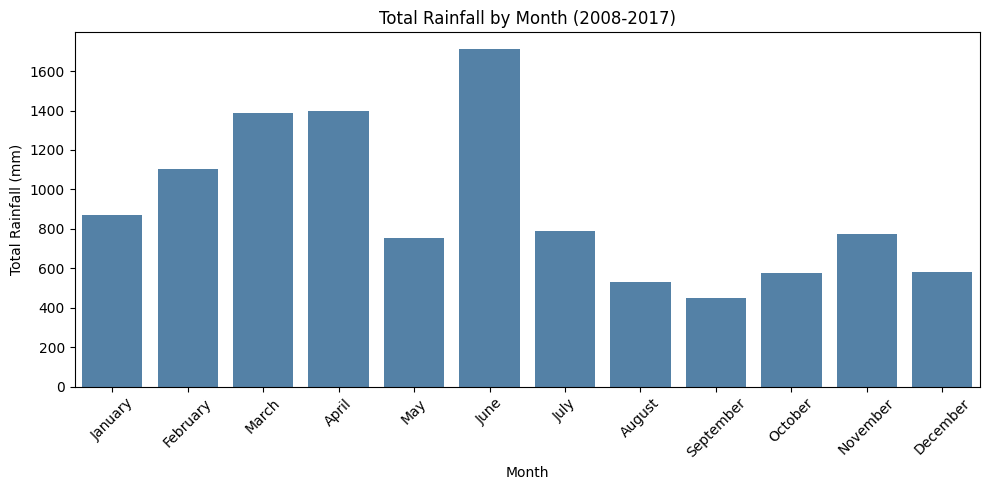

In [25]:
plt.figure(figsize= (10,5))
sns.barplot(data = monthly_rain,
           x='MonthName',
           y='Rainfall',
           color= 'steelblue')
plt.title('Total Rainfall by Month (2008-2017)')
plt.xlabel('Month')
plt.ylabel('Total Rainfall (mm)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [26]:
# Compute correlation matrix
numeric_cols.append('TempRange')

corr_matrix = df[numeric_cols].corr()
corr_matrix

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,TempRange
MinTemp,1.000000,0.771005,0.013995,0.569316,-0.063475,0.127792,-0.298040,0.225905,0.053946,0.273269,-0.391654,-0.353334,0.241248,0.164028,0.939307,0.753147,-0.358834
MaxTemp,0.771005,1.000000,-0.139306,0.510334,0.327422,0.073184,-0.349382,0.155542,-0.185382,-0.150741,-0.385853,-0.420375,-0.084695,-0.099217,0.858639,0.960805,0.317754
Rainfall,0.013995,-0.139306,1.000000,-0.110343,-0.308962,0.149811,0.153696,0.039415,0.332636,0.305635,-0.037561,0.001780,0.245231,0.200999,-0.054297,-0.142748,-0.225019
Evaporation,0.569316,0.510334,-0.110343,1.000000,0.175932,0.245426,-0.077532,0.292469,-0.395651,-0.102295,-0.343581,-0.298303,-0.037051,-0.038422,0.606122,0.474599,-0.099656
Sunshine,-0.063475,0.327422,-0.308962,0.175932,1.000000,-0.029032,-0.058410,0.177813,-0.490631,-0.586476,-0.047789,-0.094507,-0.665014,-0.677861,0.113891,0.345528,0.574411
WindGustSpeed,0.127792,0.073184,0.149811,0.245426,-0.029032,1.000000,0.256460,0.509825,-0.225613,-0.095037,-0.408876,-0.351850,0.024275,0.044016,0.159570,0.036216,-0.083003
WindSpeed9am,-0.298040,-0.349382,0.153696,-0.077532,-0.058410,0.256460,1.000000,0.197669,-0.189763,-0.148849,0.003737,0.091878,-0.062441,-0.018030,-0.334084,-0.351836,-0.068339
WindSpeed3pm,0.225905,0.155542,0.039415,0.292469,0.177813,0.509825,0.197669,1.000000,-0.288910,-0.135039,-0.333810,-0.277749,-0.050932,-0.095435,0.280009,0.136713,-0.108372
Humidity9am,0.053946,-0.185382,0.332636,-0.395651,-0.490631,-0.225613,-0.189763,-0.288910,1.000000,0.657933,0.262098,0.249202,0.431550,0.331062,-0.145944,-0.155192,-0.352036
Humidity3pm,0.273269,-0.150741,0.305635,-0.102295,-0.586476,-0.095037,-0.148849,-0.135039,0.657933,1.000000,0.151608,0.179611,0.463529,0.472248,0.131855,-0.212696,-0.627811


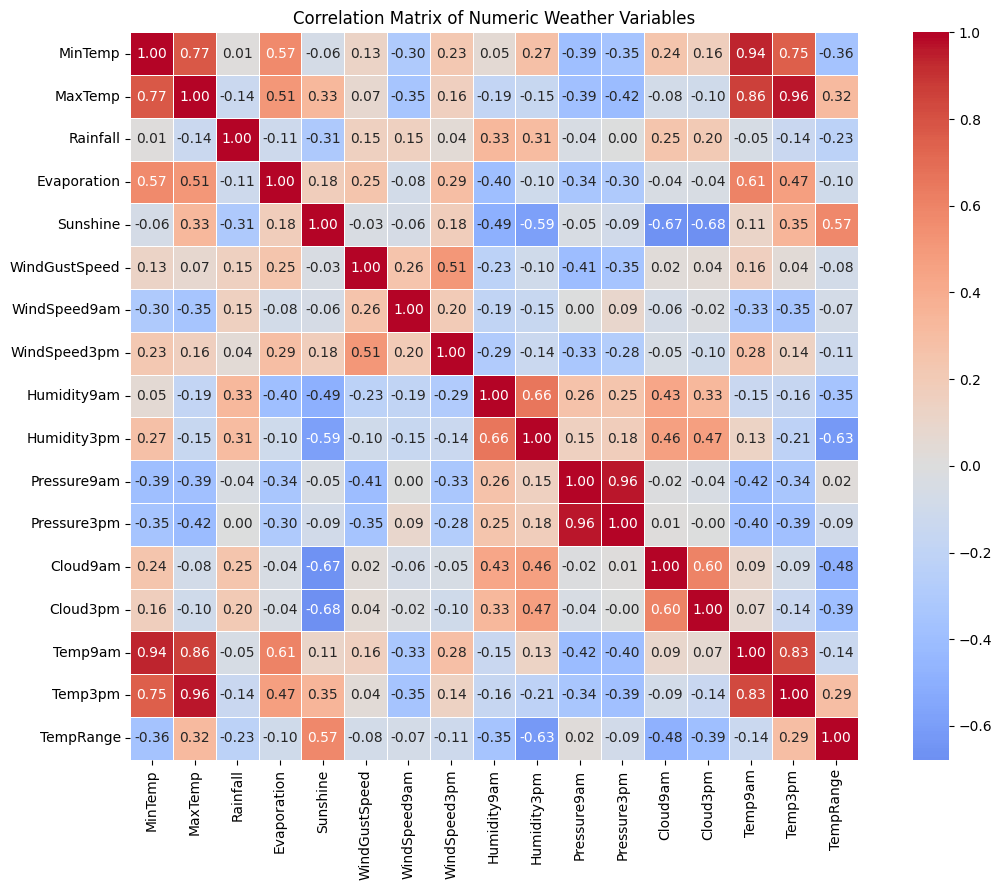

In [27]:
plt.figure(figsize=(12,9))
sns.heatmap(corr_matrix,annot=True,
            fmt='.2f',
            cmap='coolwarm', 
            center=0,
            square= True,
            linewidths=0.5)
plt.title('Correlation Matrix of Numeric Weather Variables')
plt.tight_layout()

plt.show()

In [28]:
# Humidity vs rainfall
fig = px.scatter(
    df,
    x='Humidity3pm',
    y='Rainfall',
    color = 'RainTomorrow',
    hover_data = ['Date','MaxTemp'],
    title= 'Humidity (3pm) vs Rainfall, colored by RainTomorrow',
    labels= {'Humidity3pm': 'Humidity at 3pm (%)', 'Rainfall': 'Rainfall (mm)'}
)

fig.show()

In [29]:
# Wind speed by direction
wind_summary = df.groupby('WindGustDir', observed=True).agg(
    AvgSpeed= ('WindGustSpeed', 'mean'),
    Count=('WindGustSpeed', 'count')
).reset_index()

dir_order = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE',
             'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']

wind_summary['WindGustDir'] = pd.Categorical(wind_summary['WindGustDir'],
                                            categories=dir_order,
                                           ordered=True)
wind_summary=wind_summary.sort_values('WindGustDir')

wind_summary

,WindGustDir,AvgSpeed,Count
3,N,35.466667,30
5,NNE,41.919463,149
4,NE,42.863905,169
1,ENE,36.098131,214
0,E,33.254098,122
2,ESE,37.457143,140
9,SE,42.397059,68
10,SSE,45.163180,239
8,S,49.284024,169
11,SSW,45.539877,163


In [30]:
fig = px.bar_polar(
    wind_summary,
    r= 'AvgSpeed',
    theta= 'WindGustDir',
    color= 'AvgSpeed',
    color_continuous_scale='Blues',
    title='Average Wind Gust Speed by Direction'
)

fig.show()

# Anomaly detection

In [31]:

anomaly_features = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                     'WindGustSpeed', 'Humidity9am', 'Humidity3pm',
                     'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm']

X = df[anomaly_features]
X.shape


(3271, 12)

In [32]:
iso_model = IsolationForest(contamination = 0.03, random_state=42)
df['Anomaly']= iso_model.fit_predict(X)
df['AnomalyScore'] = iso_model.decision_function(X)

df['Anomaly'] =df['Anomaly'].map({-1:'Anomaly', 1:'Normal'})
df['Anomaly'].value_counts()

Anomaly
Normal     3172
Anomaly      99
Name: count, dtype: int64

In [33]:
df.groupby('Anomaly')[anomaly_features].mean()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm
Anomaly,,,,,,,,,,,,
Anomaly,16.463636,25.442424,20.870707,7.129293,5.858586,57.606061,61.191919,49.363636,1010.307071,1009.009091,4.717172,4.595960
Normal,14.827585,22.929508,2.795082,5.114817,7.209868,40.972888,68.464061,54.865069,1018.584962,1016.221372,4.306116,4.162989


In [34]:
df.nsmallest(5, 'AnomalyScore')[['Date', 'MinTemp', 'MaxTemp', 'Rainfall',
                                    'Humidity9am', 'Pressure9am', 'AnomalyScore']]

,Date,MinTemp,MaxTemp,Rainfall,Humidity9am,Pressure9am,AnomalyScore
2890,2016-06-05,16.3,19.7,93.8,89,1002.5,-0.071906
2483,2015-04-21,14.5,17.7,119.4,87,1019.6,-0.059674
2701,2015-11-26,22.4,37.8,0.0,31,999.8,-0.059363
3078,2016-12-14,27.1,37.2,0.0,23,1008.5,-0.058575
3113,2017-01-18,25.1,38.1,0.0,26,1005.4,-0.055799


In [35]:
fig = px.scatter(
    df,
    x='Date',
    y='Rainfall',
    color= 'Anomaly',
    color_discrete_map={'Normal': 'lightblue', 'Anomaly': 'red'},
    hover_data=['MaxTemp', 'Humidity9am', 'Pressure9am'],
    title='Anomalous Days Over Time (by Rainfall)'
)

fig.show()

Two main types: extreme rainfall (high humidity, low pressure) and extreme heat-dry days
Anomalies cluster around season-transition months (Sep-Oct-Dec)

In [36]:
export_cols = ['Date', 'Year', 'Month', 'MonthName', 'Season', 'DayOfWeek',
               'MinTemp', 'MaxTemp', 'TempRange', 'Rainfall', 'Evaporation', 'Sunshine',
               'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
               'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
               'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
               'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow',
               'RainToday_Flag', 'RainTomorrow_Flag', 'Anomaly', 'AnomalyScore']


df_export = df[export_cols]
df_export.to_csv('CleanedWeatherData.csv', index=False)
print(df_export.shape)

(3271, 32)
